In [1]:
!pip install -q transformers datasets peft accelerate evaluate scikit-learn
import torch; print(torch.cuda.is_available())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.1 MB/s eta 0:00:00
True


In [2]:
import os, gc, time, random
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          AutoModelForCausalLM, TrainingArguments, Trainer,
                          DataCollatorWithPadding, set_seed)
from peft import LoraConfig, TaskType, get_peft_model
from sklearn.metrics import accuracy_score, f1_score

from google.colab import drive
drive.mount("/content/drive")

# everything lives on drive so a disconnect does not wipe results
OUT = "/content/drive/MyDrive/lora_study"
os.makedirs(f"{OUT}/preds", exist_ok=True)
os.makedirs(f"{OUT}/figures", exist_ok=True)
CSV = f"{OUT}/metrics.csv"

# note to self: these stay fixed for every run, only the variable I study changes
N_TRAIN, N_VAL, N_TEST = 4000, 500, 2000
MAX_LEN = 128
EPOCHS = 1
SPLIT_SEED = 42

MODELS = {
    "distil": "distilbert-base-uncased",   # only for debugging the pipeline
    "qwen": "Qwen/Qwen2.5-0.5B",           # main model
    "smol": "HuggingFaceTB/SmolLM2-135M",  # fallback if full FT of qwen runs out of memory
}
# layer names differ per model, wrong name = LoRA attaches to nothing
TARGETS = {
    "distil": ["q_lin", "v_lin"],
    "qwen": ["q_proj", "v_proj"],
    "smol": ["q_proj", "v_proj"],
}

Mounted at /content/drive


In [3]:
_raw = {}
def load_raw():
    # same subsample every time because the split seed is fixed
    if "splits" not in _raw:
        # note to self: ag_news now lives under fancyzhx, short name fails
        ds = load_dataset("fancyzhx/ag_news")
        tr = ds["train"].shuffle(seed=SPLIT_SEED)
        te = ds["test"].shuffle(seed=SPLIT_SEED)
        _raw["splits"] = (
            tr.select(range(N_TRAIN)),
            tr.select(range(N_TRAIN, N_TRAIN + N_VAL)),
            te.select(range(N_TEST)),
        )
    return _raw["splits"]

_tok_cache = {}
def get_data(model_key):
    # tokenize once per model, each model has its own tokenizer
    if model_key in _tok_cache:
        return _tok_cache[model_key]
    tok = AutoTokenizer.from_pretrained(MODELS[model_key])
    if tok.pad_token is None:      # batching breaks without a pad token
        tok.pad_token = tok.eos_token
    train, val, test = load_raw()

    def enc(batch):
        return tok(batch["text"], truncation=True, max_length=MAX_LEN)

    # Trainer expects the column to be called "labels"
    prep = lambda d: d.map(enc, batched=True, remove_columns=["text"]).rename_column("label", "labels")
    out = (tok, prep(train), prep(val), prep(test))
    _tok_cache[model_key] = out
    return out

In [4]:
def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

def log_row(row):
    # append to csv right after every run so nothing is lost on disconnect
    df = pd.DataFrame([row])
    if os.path.exists(CSV):
        df = pd.concat([pd.read_csv(CSV), df], ignore_index=True)
    df.to_csv(CSV, index=False)

def already_done(run_id):
    return os.path.exists(CSV) and run_id in set(pd.read_csv(CSV)["run_id"])


def run(model_key, method, rank=0, lr=2e-4, seed=0, bs=16, grad_accum=1, grad_ckpt=False):
    # method is one of: "lora", "probe", "full"
    run_id = f"{method}_{model_key}_r{rank}_lr{lr}_s{seed}"
    if already_done(run_id):          # lets me rerun a whole loop safely
        print("skip", run_id)
        return
    print("running", run_id)

    set_seed(seed)
    tok, train_ds, val_ds, test_ds = get_data(model_key)

    # fp32 weights + fp16 autocast, loading in fp16 breaks the grad scaler
    model = AutoModelForSequenceClassification.from_pretrained(
        MODELS[model_key], num_labels=4, dtype=torch.float32)
    model.config.pad_token_id = tok.pad_token_id   # Qwen needs this to find the last token

    if method == "lora":
        cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=rank, lora_alpha=2 * rank,
                         lora_dropout=0.05, target_modules=TARGETS[model_key])
        model = get_peft_model(model, cfg)    # SEQ_CLS keeps the head trainable too
    elif method == "probe":
        for n, p in model.named_parameters():
            # freeze everything except the classification head
            p.requires_grad = any(k in n for k in ["score", "classifier"])
    # method == "full": leave everything trainable

    trainable, total = count_params(model)

    # warmup_ratio is gone in new transformers, so I compute the steps myself
    total_steps = (N_TRAIN // (bs * grad_accum)) * EPOCHS
    warmup = max(1, int(0.1 * total_steps))

    args = TrainingArguments(
        output_dir="/content/tmp",
        per_device_train_batch_size=bs,
        per_device_eval_batch_size=32,
        gradient_accumulation_steps=grad_accum,
        learning_rate=lr,
        num_train_epochs=EPOCHS,
        warmup_steps=warmup,
        lr_scheduler_type="linear",
        fp16=True,
        seed=seed,
        save_strategy="no",
        report_to="none",
        logging_steps=50,
        remove_unused_columns=False,   # already dropped "text" myself
        gradient_checkpointing=grad_ckpt,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds,
                      data_collator=DataCollatorWithPadding(tok),
                      processing_class=tok)

    torch.cuda.reset_peak_memory_stats()   # so memory is per run, not cumulative
    t0 = time.time()
    trainer.train()
    train_time = time.time() - t0
    peak_mb = torch.cuda.max_memory_allocated() / 1e6

    val_loss = trainer.evaluate(val_ds)["eval_loss"]
    out = trainer.predict(test_ds)
    logits = out.predictions[0] if isinstance(out.predictions, tuple) else out.predictions
    preds = logits.argmax(-1)
    np.save(f"{OUT}/preds/{run_id}.npy", preds)   # keeping these for error analysis

    row = dict(run_id=run_id, method=method, model=model_key, rank=rank, lr=lr,
               seed=seed, epochs=EPOCHS, trainable_params=trainable,
               total_params=total, trainable_pct=100 * trainable / total,
               accuracy=accuracy_score(out.label_ids, preds),
               macro_f1=f1_score(out.label_ids, preds, average="macro"),
               val_loss=val_loss, train_time_sec=train_time, peak_gpu_mem_mb=peak_mb)
    log_row(row)
    print({k: round(row[k], 4) for k in
           ["accuracy", "macro_f1", "trainable_pct", "train_time_sec", "peak_gpu_mem_mb"]})

    del model, trainer
    gc.collect()
    torch.cuda.empty_cache()

In [5]:
# note to self: torchao is not needed here, it just clashes with peft
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [6]:
# goal: one number out, if this works the pipeline works
run("distil", "lora", rank=8, lr=2e-4, seed=0)

skip lora_distil_r8_lr0.0002_s0


In [16]:
# check train_time_sec here, it decides how much of the grid fits today
run("qwen", "lora", rank=8, lr=2e-4, seed=0)
pd.read_csv(CSV).tail()

running lora_qwen_r8_lr0.0002_s0


config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,3.447996
100,0.653078
150,0.413074
200,0.430426
250,0.319275


Training Loss,Validation Loss,Step
0.319275,0.306269,250


{'accuracy': 0.885, 'macro_f1': 0.8861, 'trainable_pct': 0.11, 'train_time_sec': 55.2819, 'peak_gpu_mem_mb': 5293.4252}


,run_id,method,model,rank,lr,seed,epochs,trainable_params,total_params,trainable_pct,accuracy,macro_f1,val_loss,train_time_sec,peak_gpu_mem_mb
0,lora_distil_r8_lr0.0002_s0,lora,distil,8,0.0002,0,1,741124,67697672,1.094756,0.8815,0.882395,0.297446,10.742395,721.112576
1,lora_qwen_r8_lr0.0002_s0,lora,qwen,8,0.0002,0,1,544256,494580608,0.110044,0.8850,0.886066,0.306269,55.281886,5293.425152


In [17]:
# probe: only the head trains, so a higher lr is fine
for seed in [0, 1, 2]:
    run("qwen", "probe", lr=1e-3, seed=seed)

running probe_qwen_r0_lr0.001_s0


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,2.542827
100,0.625486
150,0.562733
200,0.551525
250,0.443040


Training Loss,Validation Loss,Step
0.443040,0.421104,250


...

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,1.406743
100,0.727319
150,0.522922
200,0.539539
250,0.365436


Training Loss,Validation Loss,Step
0.365436,0.427130,250


{'accuracy': 0.866, 'macro_f1': 0.8678, 'trainable_pct': 0.0007, 'train_time_sec': 26.3795, 'peak_gpu_mem_mb': 2088.5417}


In [18]:
LABELS = ["World", "Sports", "Business", "Technology"]   # same order as ag_news labels 0-3

def run_fewshot():
    run_id = "fewshot_qwen_r0_lr0_s0"
    if already_done(run_id):
        print("skip", run_id)
        return

    tok = AutoTokenizer.from_pretrained(MODELS["qwen"])
    tok.padding_side = "left"       # left pad so the last position is the real last token
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    lm = AutoModelForCausalLM.from_pretrained(MODELS["qwen"], dtype=torch.float16).cuda().eval()

    train, _, test = load_raw()
    # one example per class as the shots, texts cut short to keep prompts small
    shots = []
    for c in range(4):
        ex = next(e for e in train if e["label"] == c)
        shots.append(f"Article: {ex['text'][:300]}\nTopic: {LABELS[c]}\n\n")
    random.Random(0).shuffle(shots)   # shuffled so the last shot is not biased to one class
    prefix = "".join(shots)

    # compare next-token logits of the first token of each label, rough but fine for a baseline
    label_ids = [tok.encode(" " + l)[0] for l in LABELS]

    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    preds = []
    with torch.no_grad():
        for i in range(0, len(test), 8):
            texts = test[i:i + 8]["text"]
            prompts = [f"{prefix}Article: {t[:300]}\nTopic:" for t in texts]
            enc = tok(prompts, return_tensors="pt", padding=True).to("cuda")
            logits = lm(**enc).logits[:, -1, :]
            preds += logits[:, label_ids].argmax(-1).cpu().tolist()

    labels = test["label"]
    row = dict(run_id=run_id, method="fewshot", model="qwen", rank=0, lr=0, seed=0,
               epochs=0, trainable_params=0,
               total_params=sum(p.numel() for p in lm.parameters()),
               trainable_pct=0.0, accuracy=accuracy_score(labels, preds),
               macro_f1=f1_score(labels, preds, average="macro"),
               val_loss=np.nan, train_time_sec=time.time() - t0,
               peak_gpu_mem_mb=torch.cuda.max_memory_allocated() / 1e6)
    log_row(row)
    print(round(row["accuracy"], 4), round(row["macro_f1"], 4))
    del lm
    gc.collect()
    torch.cuda.empty_cache()

run_fewshot()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

0.7675 0.7564


In [19]:
# runs take about a minute each, so I added ranks 1 and 2 to see the low end of the curve
# rank 8 seed 0 is already in the csv and gets skipped
for rank in [1, 2, 4, 8, 16, 32]:
    for seed in [0, 1, 2]:
        run("qwen", "lora", rank=rank, lr=2e-4, seed=seed)

running lora_qwen_r1_lr0.0002_s0


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,3.814754
100,0.788551
150,0.566111
200,0.559850
250,0.445244


Training Loss,Validation Loss,Step
0.445244,0.424431,250


...

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,1.654275
100,0.508872
150,0.368434
200,0.341364
250,0.270274


Training Loss,Validation Loss,Step
0.270274,0.277641,250


{'accuracy': 0.8945, 'macro_f1': 0.8957, 'trainable_pct': 0.4366, 'train_time_sec': 60.9242, 'peak_gpu_mem_mb': 5359.3667}


In [8]:
# lr 2e-4 is already covered by the main sweep, so only 1e-4 and 5e-4 here
for rank in [8, 32]:
    for lr in [1e-4, 5e-4]:
        for seed in [0, 1, 2]:
            run("qwen", "lora", rank=rank, lr=lr, seed=seed)

running lora_qwen_r8_lr0.0001_s0


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,4.311321
100,1.062639
150,0.626360
200,0.569393
250,0.425152


Training Loss,Validation Loss,Step
0.425152,0.429157,250


...

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,1.339570
100,0.488095
150,0.389389
200,0.346482
250,0.257829


Training Loss,Validation Loss,Step
0.257829,0.254531,250


{'accuracy': 0.903, 'macro_f1': 0.9039, 'trainable_pct': 0.4366, 'train_time_sec': 57.6242, 'peak_gpu_mem_mb': 5357.4006}


In [9]:
# r32 was still improving, so I push the rank up to find where it flattens
# cell 10 groups by rank, so these show up in the plots automatically
for rank in [64, 128]:
    for seed in [0, 1, 2]:
        run("qwen", "lora", rank=rank, lr=2e-4, seed=seed)

running lora_qwen_r64_lr0.0002_s0


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,2.604313
100,0.493282
150,0.412376
200,0.370384
250,0.312585


Training Loss,Validation Loss,Step
0.312585,0.281291,250


...

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,1.411576
100,0.465922
150,0.367468
200,0.348891
250,0.263612


Training Loss,Validation Loss,Step
0.263612,0.265948,250


{'accuracy': 0.8985, 'macro_f1': 0.8992, 'trainable_pct': 1.7216, 'train_time_sec': 58.3097, 'peak_gpu_mem_mb': 5466.7638}


In [10]:
# full FT needs a much lower lr than LoRA, small batch + accumulation to save memory
try:
    run("qwen", "full", lr=2e-5, seed=0, bs=4, grad_accum=4, grad_ckpt=True)
except torch.cuda.OutOfMemoryError:
    print("OOM: restart runtime, rerun cells 1-3, then use the smol fallback and say so in the README")

running full_qwen_r0_lr2e-05_s0


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,8.977910
100,2.320034
150,1.390379
200,1.277899
250,1.148258


Training Loss,Validation Loss,Step
1.148258,0.223728,250


{'accuracy': 0.915, 'macro_f1': 0.9158, 'trainable_pct': 100.0, 'train_time_sec': 232.3248, 'peak_gpu_mem_mb': 8745.9031}


In [11]:
# best lr sits at the edge of my grid, so I check 1e-3 to see where it turns over
for rank in [8, 32]:
    for seed in [0, 1, 2]:
        run("qwen", "lora", rank=rank, lr=1e-3, seed=seed)

running lora_qwen_r8_lr0.001_s0


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,2.356987
100,0.563427
150,0.482377
200,0.385435
250,0.306649


Training Loss,Validation Loss,Step
0.306649,0.275674,250


...

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,1.483521
100,0.512806
150,0.426313
200,0.379793
250,0.242163


Training Loss,Validation Loss,Step
0.242163,0.260663,250


{'accuracy': 0.902, 'macro_f1': 0.9027, 'trainable_pct': 0.4366, 'train_time_sec': 57.5311, 'peak_gpu_mem_mb': 5358.4492}


In [12]:
# probe comparison was at one lr only, so I retest the low ranks at 5e-4
for rank in [1, 2, 4]:
    for seed in [0, 1, 2]:
        run("qwen", "lora", rank=rank, lr=5e-4, seed=seed)

running lora_qwen_r1_lr0.0005_s0


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,2.817514
100,0.595140
150,0.466824
200,0.441765
250,0.341221


Training Loss,Validation Loss,Step
0.341221,0.340270,250


...

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,1.522718
100,0.508276
150,0.367647
200,0.368719
250,0.272743


Training Loss,Validation Loss,Step
0.272743,0.296888,250


{'accuracy': 0.893, 'macro_f1': 0.8943, 'trainable_pct': 0.0554, 'train_time_sec': 57.4993, 'peak_gpu_mem_mb': 5326.5516}


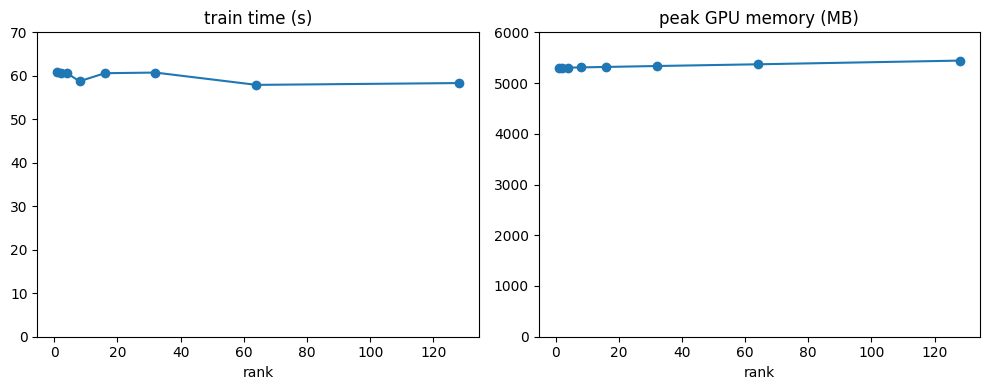

In [10]:
# note to self: zoomed axis made flat time look noisy, so both start from 0
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
g4["train_time_sec"].plot(marker="o", ax=ax[0], title="train time (s)", ylim=(0, 70))
g4["peak_gpu_mem_mb"].plot(marker="o", ax=ax[1], title="peak GPU memory (MB)", ylim=(0, 6000))
plt.tight_layout()
plt.savefig(f"{OUT}/figures/cost_vs_rank.png", dpi=200); plt.show()

                     macro_f1         accuracy         trainable_pct      train_time_sec         peak_gpu_mem_mb         
                         mean     std     mean     std          mean  std           mean     std            mean      std
method  rank lr                                                                                                          
fewshot 0    0.00000   0.7564     NaN   0.7675     NaN        0.0000  NaN        40.1415     NaN       2304.7219      NaN
full    0    0.00002   0.9158     NaN   0.9150     NaN      100.0000  NaN       232.3248     NaN       8745.9031      NaN
lora    1    0.00020   0.8525  0.0033   0.8512  0.0038        0.0144  0.0        60.8885  0.9627       5300.8539  20.4605
             0.00050   0.8815  0.0014   0.8803  0.0018        0.0144  0.0        57.2241  0.2615       5299.3138  21.0488
        2    0.00020   0.8640  0.0050   0.8627  0.0054        0.0281  0.0        60.6906  0.0570       5301.9691  20.4605
             0.00050   0

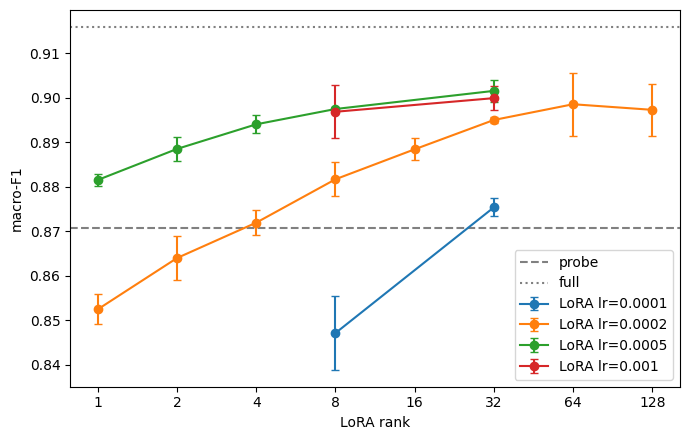

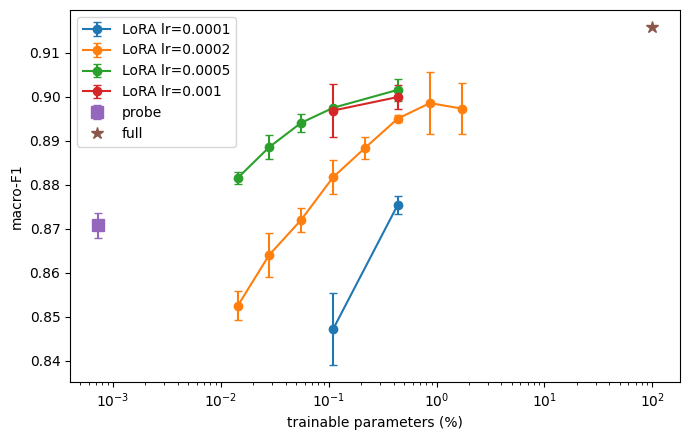

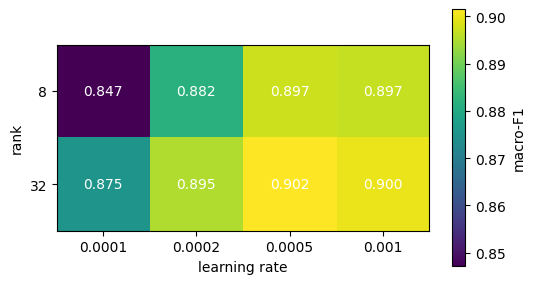

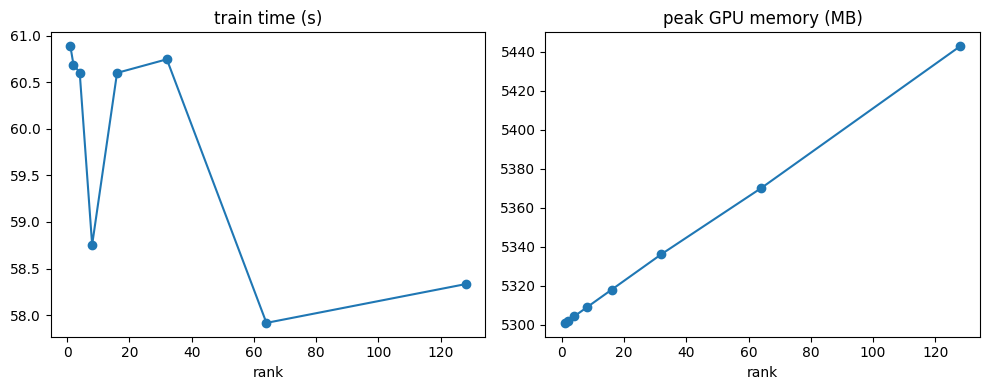

In [11]:
import matplotlib.pyplot as plt

df = pd.read_csv(CSV)
q = df[df["model"] == "qwen"].copy()   # note to self: q["rank"], q.rank is a pandas method
lora = q[q["method"] == "lora"]

cols = ["macro_f1", "accuracy", "trainable_pct", "train_time_sec", "peak_gpu_mem_mb"]
table = q.groupby(["method", "rank", "lr"])[cols].agg(["mean", "std"]).round(4)
print(table.to_string())
table.to_csv(f"{OUT}/summary_table.csv")

# plot 1: F1 vs rank, one line per learning rate, probe and full as reference lines
plt.figure(figsize=(7, 4.5))
for lr_, d in lora.groupby("lr"):
    g_ = d.groupby("rank")["macro_f1"].agg(["mean", "std"])
    plt.errorbar(g_.index, g_["mean"], yerr=g_["std"], marker="o", capsize=3, label=f"LoRA lr={lr_}")
for m, ls in [("probe", "--"), ("full", ":")]:
    s = q[q["method"] == m]["macro_f1"]
    if len(s):
        plt.axhline(s.mean(), linestyle=ls, color="gray", label=m)
plt.xscale("log", base=2)
plt.xticks(sorted(lora["rank"].unique()), sorted(lora["rank"].unique()))
plt.xlabel("LoRA rank"); plt.ylabel("macro-F1"); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/figures/f1_vs_rank.png", dpi=200); plt.show()

# plot 2: F1 vs trainable %, the efficiency plot (probe and full FT included)
plt.figure(figsize=(7, 4.5))
for lr_, d in lora.groupby("lr"):
    g_ = d.groupby("rank").agg(pct=("trainable_pct", "mean"),
                               f1=("macro_f1", "mean"), sd=("macro_f1", "std"))
    plt.errorbar(g_["pct"], g_["f1"], yerr=g_["sd"], marker="o", capsize=3, label=f"LoRA lr={lr_}")
for m, mk in [("probe", "s"), ("full", "*")]:
    d = q[q["method"] == m]
    if len(d):
        err = d["macro_f1"].std() if len(d) > 1 else None
        plt.errorbar(d["trainable_pct"].mean(), d["macro_f1"].mean(), yerr=err,
                     marker=mk, markersize=9, linestyle="none", capsize=3, label=m)
plt.xscale("log")
plt.xlabel("trainable parameters (%)"); plt.ylabel("macro-F1"); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/figures/f1_vs_params.png", dpi=200); plt.show()

# plot 3: rank x lr heatmap
ab = lora[lora["rank"].isin([8, 32])]
pv = ab.pivot_table(index="rank", columns="lr", values="macro_f1", aggfunc="mean")
plt.figure(figsize=(5.5, 3))
plt.imshow(pv.values, cmap="viridis")
plt.colorbar(label="macro-F1")
plt.xticks(range(len(pv.columns)), pv.columns)
plt.yticks(range(len(pv.index)), pv.index)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        plt.text(j, i, f"{pv.values[i, j]:.3f}", ha="center", va="center", color="white")
plt.xlabel("learning rate"); plt.ylabel("rank"); plt.tight_layout()
plt.savefig(f"{OUT}/figures/rank_x_lr.png", dpi=200); plt.show()

# plot 4: cost vs rank at lr 2e-4 (the only lr that has every rank)
main = lora[lora["lr"] == 2e-4]
g4 = main.groupby("rank")[["train_time_sec", "peak_gpu_mem_mb"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
g4["train_time_sec"].plot(marker="o", ax=ax[0], title="train time (s)")
g4["peak_gpu_mem_mb"].plot(marker="o", ax=ax[1], title="peak GPU memory (MB)")
plt.tight_layout()
plt.savefig(f"{OUT}/figures/cost_vs_rank.png", dpi=200); plt.show()

In [8]:
from sklearn.metrics import confusion_matrix, classification_report

names = ["World", "Sports", "Business", "Sci/Tech"]
_, _, test_raw = load_raw()
labels = np.array(test_raw["label"])

# best config comes from the data, not hardcoded
best_rank, best_lr = lora.groupby(["rank", "lr"])["macro_f1"].mean().idxmax()
print("best LoRA config: rank", best_rank, "lr", best_lr)

p_lora = np.load(f"{OUT}/preds/lora_qwen_r{int(best_rank)}_lr{float(best_lr)}_s0.npy")
p_full = np.load(f"{OUT}/preds/full_qwen_r0_lr2e-05_s0.npy")

for tag, p in [("best LoRA", p_lora), ("full FT", p_full)]:
    print("\n==", tag, "==")
    print(confusion_matrix(labels, p))
    print(classification_report(labels, p, target_names=names, digits=3))

# reading ~40 mistakes by hand, looking for a pattern to write up
wrong = np.where(p_lora != labels)[0]
for i in wrong[:40]:
    print(f"[true={names[labels[i]]} | pred={names[p_lora[i]]}] {test_raw[int(i)]['text'][:200]}\n")

# how many LoRA mistakes does full FT get right
fixed = np.where((p_lora != labels) & (p_full == labels))[0]
print("LoRA wrong, full FT right:", len(fixed), "of", len(wrong))

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

best LoRA config: rank 32 lr 0.0005

== best LoRA ==
[[458   9  16  14]
 [  7 474   0   2]
 [ 20   5 443  54]
 [ 22   0  55 421]]
              precision    recall  f1-score   support

       World      0.903     0.922     0.912       497
      Sports      0.971     0.981     0.976       483
    Business      0.862     0.849     0.855       522
    Sci/Tech      0.857     0.845     0.851       498

    accuracy                          0.898      2000
   macro avg      0.898     0.899     0.899      2000
weighted avg      0.898     0.898     0.898      2000


== full FT ==
[[456   9  15  17]
 [  4 479   0   0]
 [ 18   5 455  44]
 [ 10   0  48 440]]
              precision    recall  f1-score   support

       World      0.934     0.918     0.926       497
      Sports      0.972     0.992     0.982       483
    Business      0.878     0.872     0.875       522
    Sci/Tech      0.878     0.884     0.881       498

    accuracy                          0.915      2000
   macro avg     

In [9]:
# pins the versions I actually used, so the README setup section is accurate
!pip freeze | grep -E "^(torch|transformers|peft|datasets|accelerate|scikit-learn|pandas|matplotlib|numpy)==" > /content/requirements.txt
!cat /content/requirements.txt

# copy to drive next to the other results so I can download it with them
!cp /content/requirements.txt /content/drive/MyDrive/lora_study/requirements.txt

# note to self: README also needs the python version and the GPU name
import sys
print(sys.version)
!nvidia-smi --query-gpu=name --format=csv,noheader

accelerate==1.15.0
datasets==4.8.5
matplotlib==3.10.0
numpy==2.1.3
pandas==2.2.3
peft==0.21.1
scikit-learn==1.6.1
torch==2.11.0+cu130
transformers==5.18.0
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Tesla T4


In [12]:
# full FT got 1 seed and 1 lr while LoRA got 4 lrs, so I even it out
for seed in [1, 2]:
    run("qwen", "full", lr=2e-5, seed=seed, bs=4, grad_accum=4, grad_ckpt=True)
for lr in [1e-5, 5e-5]:
    run("qwen", "full", lr=lr, seed=0, bs=4, grad_accum=4, grad_ckpt=True)

running full_qwen_r0_lr2e-05_s1


config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,9.516283
100,1.980425
150,1.601381
200,1.750277
250,1.124389


Training Loss,Validation Loss,Step
1.124389,0.256308,250


{'accuracy': 0.9015, 'macro_f1': 0.9027, 'trainable_pct': 100.0, 'train_time_sec': 243.2279, 'peak_gpu_mem_mb': 8750.8787}
